# Classification Experiments, Version 3
Yang Xiao (yx752)

## Step 0: Data and Evaluation
This iteration tests nonlinear models of writing style and their combination. Model settings and blend weights are selected using out-of-fold predictions from the 8,000-row training partition. The fixed 2,000-row development partition is evaluated afterward. Dependencies: numpy, pandas, scipy, scikit-learn and matplotlib. Run the cells in order to generate the final CSV.

In [1]:
from pathlib import Path
from collections import Counter
import re, json, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

SEED=27
paths=[Path('data'),Path('.'),Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')]
DATA=next((p for p in paths if (p/'train.csv').exists()),None)
if DATA is None: raise FileNotFoundError('Place competition CSV files in data/ beside this notebook.')
OUT=Path('v3_results');OUT.mkdir(exist_ok=True)
train=pd.read_csv(DATA/'train.csv');test=pd.read_csv(DATA/'test.csv')
sample=pd.read_csv(DATA/'sample_submission.csv')
tr,va=train_test_split(np.arange(len(train)),test_size=2000,stratify=train.label,random_state=SEED)
y=train.label.to_numpy()[tr];yv=train.label.to_numpy()[va]
assert len(tr)==8000 and len(va)==2000 and train.id.is_unique
print('Training:',len(tr),'Development:',len(va),'Seed:',SEED)
train.iloc[va][['id']].to_csv(OUT/'val_ids.csv',index=False)

Training: 8000 Development: 2000 Seed: 27


## Step 1: Feature Extraction
The original 31 numeric style features are kept as an ablation. An expanded set adds token-frequency shape, word and sentence length quantiles, function-word groups, and observable punctuation/formatting patterns. A canonical variant normalizes whitespace and common typography before extraction. These functions do not use labels or corpus-level statistics. Scaling for SVM is fitted inside each fold.

In [2]:
def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

In [3]:
def expanded_features(text):
    features=extract_style_features(text)
    words=re.findall(r"[a-z]+(?:['’][a-z]+)?",text.lower())
    n=max(len(words),1);nc=max(len(text),1)
    counts=Counter(words)
    values=np.asarray(list(counts.values()),dtype=float)
    lengths=np.asarray([len(w) for w in words],dtype=float)
    sentence_text=[s for s in re.split(r'[.!?]+(?:["\'”’)]*)\s+|\n+',text) if s.strip()]
    sentence_lengths=np.asarray([len(re.findall(r'\b\w+\b',s)) for s in sentence_text],dtype=float)
    for name,array in [('token_length',lengths),('sentence_length',sentence_lengths)]:
        for q in [10,25,50,75,90]:features[f'{name}_q{q}']=float(np.percentile(array,q)) if len(array) else 0.
    features['hapax_ratio']=float(np.sum(values==1)/max(len(values),1))
    features['dislegomena_ratio']=float(np.sum(values==2)/max(len(values),1))
    features['token_entropy']=float(-np.sum((values/n)*np.log(values/n))) if len(values) else 0.
    features['top_token_fraction']=float(values.max()/n) if len(values) else 0.
    features['long_word_fraction']=float(np.mean(lengths>=8)) if len(lengths) else 0.
    features['short_word_fraction']=float(np.mean(lengths<=3)) if len(lengths) else 0.
    groups={
        'first_person':'i me my mine we us our ours',
        'second_person':'you your yours yourself yourselves',
        'third_person':'he him his she her hers they them their theirs',
        'articles':'a an the',
        'prepositions':'of in on at for from to with by about into over under between through',
        'conjunctions':'and or but so because although while whereas if unless since',
        'modals':'can could may might must shall should will would',
        'negations':"no not never neither nor cannot don't doesn't didn't isn't aren't wasn't weren't",
        'demonstratives':'this that these those',
        'be_forms':'am is are was were be been being',
        'have_forms':'have has had having',
    }
    for name,group in groups.items():features[name+'_fraction']=sum(counts[w] for w in group.split())/n
    for char,name in [('"','straight_quote'),("'",'apostrophe'),('(','open_parenthesis'),(')','close_parenthesis'),('[','bracket'),('/','slash'),('-','hyphen'),('%','percent'),(chr(10),'newline')]:
        features[name+'_per_100_words']=100*text.count(char)/n
    features['non_ascii_fraction']=sum(ord(c)>127 for c in text)/nc
    features['whitespace_fraction']=sum(c.isspace() for c in text)/nc
    features['double_space_fraction']=len(re.findall(r' {2,}',text))/nc
    features['sentence_short_fraction']=float(np.mean(sentence_lengths<8)) if len(sentence_lengths) else 0.
    features['sentence_long_fraction']=float(np.mean(sentence_lengths>30)) if len(sentence_lengths) else 0.
    features['list_line_fraction']=len(re.findall(r'(?m)^\s*(?:[-*•]|\d+[.)])\s+',text))/max(len(text.splitlines()),1)
    return features

def canonicalize(text):
    return re.sub(r'\s+',' ',str(text)).translate(str.maketrans({'’':"'",'‘':"'",'“':'"','”':'"','—':'-','–':'-','…':'...'})).strip()

start=time.perf_counter()
raw=pd.DataFrame([expanded_features(str(t)) for t in train.text])
canonical=pd.DataFrame([expanded_features(canonicalize(t)) for t in train.text])
assert np.isfinite(raw.to_numpy()).all()
base_names=list(extract_style_features('').keys())
feature_names={'base':base_names,'expanded':list(raw.columns),'canonical':list(raw.columns)}
matrices={'base':raw[base_names].to_numpy(),'expanded':raw.to_numpy(),'canonical':canonical.to_numpy()}
stress_matrices={'base':canonical[base_names].to_numpy(),'expanded':canonical.to_numpy(),'canonical':canonical.to_numpy()}
print('Base:',len(base_names),'Expanded:',raw.shape[1],f'Extraction: {time.perf_counter()-start:.1f}s')

Base: 31 Expanded: 73 Extraction: 38.4s


## Step 2: Candidate Models and Out-of-Fold Evaluation
Compare base, expanded and canonical RBF SVMs with C in {1,10} and gamma in {scale,0.01}; histogram gradient boosting with 15 or 31 leaves and L2 regularization 1 or 10; and extra trees with minimum leaf size 2 or 5. The tree models compare expanded and canonical features. All use three fixed stratified folds within the training partition. Predictions are converted to smoothed percentile ranks relative to each fitted model’s training scores. Selection maximizes the average OOF AUROC on original text and format-normalized text. This favors configurations that do not depend heavily on whitespace/typography artifacts. The shared development set was used in previous iterations and in identifying the formatting weakness; it is not an untouched final test.

Six additional configurations use training-only formatting augmentation: four boosting settings and two RBF settings. Each training fold includes originals and their canonicalized copies with sample weights 0.75 and 0.25, respectively. Copies never enter a fold held out for their original row. This produces 30 candidates in total.

In [4]:
configs=[]
for features in ['base','expanded','canonical']:
    for C in [1,10]:
        for gamma in ['scale',0.01]:configs.append({'family':'rbf','features':features,'C':C,'gamma':gamma})
for features in ['expanded','canonical']:
    for leaves in [15,31]:
        for l2 in [1,10]:configs.append({'family':'hgb','features':features,'leaves':leaves,'l2':l2})
    for leaf in [2,5]:configs.append({'family':'trees','features':features,'leaf':leaf})
for leaves in [15,31]:
    for l2 in [1,10]:configs.append({'family':'hgb','features':'expanded','leaves':leaves,'l2':l2,'augment':True})
for C in [1,10]:configs.append({'family':'rbf','features':'expanded','C':C,'gamma':'scale','augment':True})

def model_for(config):
    if config['family']=='rbf':return make_pipeline(StandardScaler(),SVC(C=config['C'],gamma=config['gamma'],kernel='rbf',cache_size=512))
    if config['family']=='hgb':return HistGradientBoostingClassifier(max_iter=250,max_leaf_nodes=config['leaves'],learning_rate=.06,l2_regularization=config['l2'],early_stopping=False,random_state=SEED)
    return ExtraTreesClassifier(n_estimators=350,min_samples_leaf=config['leaf'],max_features=.8,n_jobs=2,random_state=SEED)

def score_model(model,z):
    if hasattr(model,'decision_function'):return model.decision_function(z)
    return model.predict_proba(z)[:,1]

def fit_model(config,z,labels,zstress):
    model=model_for(config)
    if not config.get('augment',False):return model.fit(z,labels)
    fit_z=np.concatenate([z,zstress]);fit_y=np.tile(labels,2)
    weights=np.concatenate([np.full(len(labels),.75),np.full(len(labels),.25)])
    kwargs={'svc__sample_weight':weights} if hasattr(model,'named_steps') else {'sample_weight':weights}
    return model.fit(fit_z,fit_y,**kwargs)

def percentile(scores,anchors):
    anchors=np.sort(anchors)
    return (np.searchsorted(anchors,scores,side='left')+np.searchsorted(anchors,scores,side='right')+1)/(2*(len(anchors)+1))

folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(tr,y))
oof=np.zeros((len(tr),len(configs)))
stress_oof=np.zeros_like(oof)
rows=[]
for j,config in enumerate(configs):
    z=matrices[config['features']][tr]
    zs=stress_matrices[config['features']][tr]
    start=time.perf_counter();fold_aucs=[]
    for a,b in folds:
        model=fit_model(config,z[a],y[a],zs[a])
        scores=score_model(model,z[b]);anchors=score_model(model,z[a])
        oof[b,j]=percentile(scores,anchors)
        stress_oof[b,j]=percentile(score_model(model,zs[b]),anchors)
        fold_aucs.append(roc_auc_score(y[b],scores))
    normal_auc=roc_auc_score(y,oof[:,j]);stress_auc=roc_auc_score(y,stress_oof[:,j])
    rows.append({'candidate':j,**config,'oof_auroc':normal_auc,'stress_oof_auroc':stress_auc,'selection_score':(normal_auc+stress_auc)/2,'mean_fold_auroc':np.mean(fold_aucs),'std_fold_auroc':np.std(fold_aucs),'seconds':time.perf_counter()-start})
    print(j,config,'OOF:',round(normal_auc,6),'Stress:',round(stress_auc,6),flush=True)
    pd.DataFrame(rows).to_csv(OUT/'search.csv',index=False)
search=pd.DataFrame(rows).sort_values('selection_score',ascending=False)
np.save(OUT/'training_oof.npy',oof)
np.save(OUT/'training_stress_oof.npy',stress_oof)
print(search[['candidate','family','features','oof_auroc','stress_oof_auroc','selection_score']].to_string(index=False))

0 {'family': 'rbf', 'features': 'base', 'C': 1, 'gamma': 'scale'} OOF: 0.990068 Stress: 0.789147
1 {'family': 'rbf', 'features': 'base', 'C': 1, 'gamma': 0.01} OOF: 0.987679 Stress: 0.766703
2 {'family': 'rbf', 'features': 'base', 'C': 10, 'gamma': 'scale'} OOF: 0.990889 Stress: 0.801121
3 {'family': 'rbf', 'features': 'base', 'C': 10, 'gamma': 0.01} OOF: 0.99001 Stress: 0.791874
4 {'family': 'rbf', 'features': 'expanded', 'C': 1, 'gamma': 'scale'} OOF: 0.993576 Stress: 0.775415
5 {'family': 'rbf', 'features': 'expanded', 'C': 1, 'gamma': 0.01} OOF: 0.992968 Stress: 0.771554
6 {'family': 'rbf', 'features': 'expanded', 'C': 10, 'gamma': 'scale'} OOF: 0.995099 Stress: 0.77014
7 {'family': 'rbf', 'features': 'expanded', 'C': 10, 'gamma': 0.01} OOF: 0.995132 Stress: 0.771813
8 {'family': 'rbf', 'features': 'canonical', 'C': 1, 'gamma': 'scale'} OOF: 0.940863 Stress: 0.940863
9 {'family': 'rbf', 'features': 'canonical', 'C': 1, 'gamma': 0.01} OOF: 0.937114 Stress: 0.937114
10 {'family': 'rb

## Step 3: Select the Blend Using Training Predictions
Shortlist one candidate per family using the average original/stress OOF AUROC. Compare those single models, pair blends with weights 0.25/0.5/0.75, and an equal three-family blend, using the same selection criterion. Prefer fewer components on an exact tie. Fit a sigmoid mapping using the pooled original and stress OOF blend scores. The OOF score is a selection score and is optimistic after this search; it is not an unbiased final performance estimate.

In [5]:
shortlist=search.groupby('family',sort=False).head(1).candidate.astype(int).tolist()
blend_specs=[]
for j in shortlist:blend_specs.append({j:1.})
from itertools import combinations
for a,b in combinations(shortlist,2):
    for weight in [.25,.5,.75]:blend_specs.append({a:weight,b:1-weight})
blend_specs.append({j:1/len(shortlist) for j in shortlist})
blend_rows=[]
for i,spec in enumerate(blend_specs):
    scores=sum(weight*oof[:,j] for j,weight in spec.items())
    stress_scores=sum(weight*stress_oof[:,j] for j,weight in spec.items())
    normal_auc=roc_auc_score(y,scores);stress_auc=roc_auc_score(y,stress_scores)
    blend_rows.append({'blend':i,'oof_auroc':normal_auc,'stress_oof_auroc':stress_auc,'selection_score':(normal_auc+stress_auc)/2,'components':len(spec),'weights':json.dumps(spec)})
blend_table=pd.DataFrame(blend_rows).sort_values(['selection_score','components','blend'],ascending=[False,True,True])
chosen=blend_specs[int(blend_table.iloc[0].blend)]
train_oof=sum(weight*oof[:,j] for j,weight in chosen.items())
train_stress_oof=sum(weight*stress_oof[:,j] for j,weight in chosen.items())
calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(np.concatenate([train_oof,train_stress_oof]).reshape(-1,1),np.tile(y,2))
print(blend_table.head(8).to_string(index=False))
print('Chosen:',{j:{'weight':w,'config':configs[j]} for j,w in chosen.items()})
blend_table.to_csv(OUT/'blend_search.csv',index=False)

 blend  oof_auroc  stress_oof_auroc  selection_score  components                                                                        weights
     5   0.996116          0.952746         0.974431           2                                                       {"26": 0.75, "29": 0.25}
    12   0.993718          0.954766         0.974242           3 {"26": 0.3333333333333333, "29": 0.3333333333333333, "23": 0.3333333333333333}
     0   0.995784          0.951101         0.973442           1                                                                    {"26": 1.0}
     8   0.994157          0.952268         0.973213           2                                                       {"26": 0.75, "23": 0.25}
     4   0.995653          0.949759         0.972706           2                                                         {"26": 0.5, "29": 0.5}
    11   0.992036          0.951762         0.971899           2                                                       {"29": 0.75, "23"

## Step 4: Fixed Development Evaluation and Formatting Stress Test
Fit the selected components using only the training partition, then evaluate the original held-out text. As a separate diagnostic, collapse whitespace and normalize common curly quotes/dashes. These transformations do not change the supplied labels. A performance drop under them indicates formatting sensitivity; it is not an estimate of the actual Kaggle distribution. Development stress scores are not used to choose blend weights; the corresponding training OOF diagnostic is part of the selection criterion.

Chosen blend development AUROC: 0.997980
Development log loss: 0.065634
Whitespace/typography stress AUROC: 0.956759
<=150 403 AUROC=0.995777
151-250 1036 AUROC=0.998033
>250 561 AUROC=0.999071


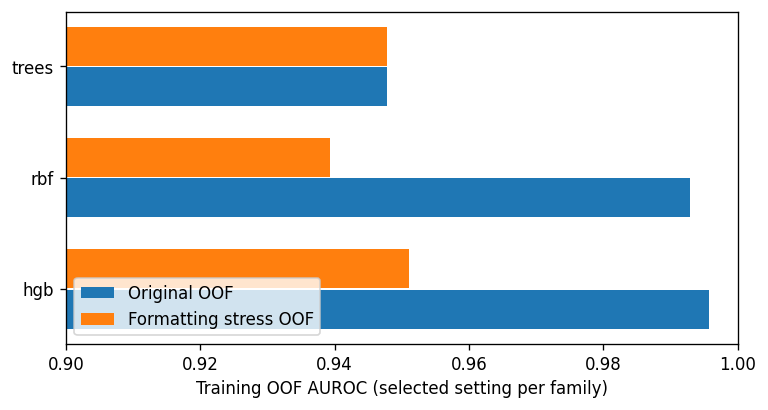

In [6]:
fitted={};anchors={};dev_rank=np.zeros(len(va))
for j,weight in chosen.items():
    config=configs[j];columns=feature_names[config['features']]
    z=matrices[config['features']]
    fitted[j]=fit_model(config,z[tr],y,stress_matrices[config['features']][tr])
    anchors[j]=score_model(fitted[j],z[tr])
    dev_rank+=weight*percentile(score_model(fitted[j],z[va]),anchors[j])
dev_probability=calibrator.predict_proba(dev_rank.reshape(-1,1))[:,1]
dev_auc=roc_auc_score(yv,dev_probability)
print(f'Chosen blend development AUROC: {dev_auc:.6f}')
print(f'Development log loss: {log_loss(yv,dev_probability):.6f}')
validation=pd.DataFrame({'id':train.id.to_numpy()[va],'label':yv,'probability':dev_probability,'words':train.text.iloc[va].str.split().str.len().to_numpy()})
validation.to_csv(OUT/'validation_predictions.csv',index=False)
stress_rank=np.zeros(len(va))
for j,weight in chosen.items():
    stress_rank+=weight*percentile(score_model(fitted[j],stress_matrices[configs[j]['features']][va]),anchors[j])
stress_auc=roc_auc_score(yv,stress_rank)
print(f'Whitespace/typography stress AUROC: {stress_auc:.6f}')
for name,g in validation.groupby(pd.cut(validation.words,[0,150,250,np.inf],labels=['<=150','151-250','>250']),observed=True):
    print(name,len(g),f'AUROC={roc_auc_score(g.label,g.probability):.6f}')
plot_rows=search.groupby('family',sort=False).head(1)
positions=np.arange(len(plot_rows))
fig,ax=plt.subplots(figsize=(6.5,3.5))
ax.barh(positions-.18,plot_rows.oof_auroc,height=.35,label='Original OOF')
ax.barh(positions+.18,plot_rows.stress_oof_auroc,height=.35,label='Formatting stress OOF')
ax.set_yticks(positions,plot_rows.family)
ax.set_xlim(.90,1.0)
ax.set_xlabel('Training OOF AUROC (selected setting per family)')
ax.legend(loc='lower left')
fig.tight_layout()
plt.show()
summary={'seed':SEED,'selected_components':{j:{'weight':w,'config':configs[j]} for j,w in chosen.items()},'selection_oof_auroc':float(blend_table.iloc[0].oof_auroc),'development_auroc':dev_auc,'formatting_stress_auroc':stress_auc}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))

## Step 5: Full-Data Predictions
Keep the selected configurations and weights fixed. Regenerate OOF scores on all 10,000 labeled rows to fit the final sigmoid mapping, then refit each selected component on all labeled rows. Test text is transformed only after selection. Neither external labels nor unlabeled pseudo-labels are used.

In [7]:
yfull=train.label.to_numpy();full_folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,yfull))
test_raw=pd.DataFrame([expanded_features(str(t)) for t in test.text])
test_canonical=pd.DataFrame([expanded_features(canonicalize(t)) for t in test.text])
test_matrices={'base':test_raw[base_names].to_numpy(),'expanded':test_raw.to_numpy(),'canonical':test_canonical.to_numpy()}
full_oof=np.zeros(len(train));test_rank=np.zeros(len(test))
full_stress_oof=np.zeros(len(train))
for j,weight in chosen.items():
    config=configs[j];columns=feature_names[config['features']]
    z=matrices[config['features']];zt=test_matrices[config['features']]
    zs=stress_matrices[config['features']]
    part=np.zeros(len(train))
    part_stress=np.zeros(len(train))
    for a,b in full_folds:
        model=fit_model(config,z[a],yfull[a],zs[a])
        part[b]=percentile(score_model(model,z[b]),score_model(model,z[a]))
        part_stress[b]=percentile(score_model(model,zs[b]),score_model(model,z[a]))
    full_oof+=weight*part
    full_stress_oof+=weight*part_stress
    model=fit_model(config,z,yfull,zs)
    test_rank+=weight*percentile(score_model(model,zt),score_model(model,z))
    print('Refitted component',j,config,flush=True)
final_calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(np.concatenate([full_oof,full_stress_oof]).reshape(-1,1),np.tile(yfull,2))
submission=pd.DataFrame({'id':test.id,'label':final_calibrator.predict_proba(test_rank.reshape(-1,1))[:,1]})
submission=submission.set_index('id').loc[sample.id].reset_index()
assert list(submission)==['id','label'] and len(submission)==3000 and submission.id.is_unique
assert submission.id.tolist()==sample.id.tolist() and set(submission.id)==set(test.id)
assert np.isfinite(submission.label).all() and submission.label.between(0,1).all()
submission.to_csv(OUT/'submission_yx752_v3.csv',index=False)
print('Saved 3,000 test probabilities to v3_results/submission_yx752_v3.csv')

Refitted component 26 {'family': 'hgb', 'features': 'expanded', 'leaves': 31, 'l2': 1, 'augment': True}
Refitted component 29 {'family': 'rbf', 'features': 'expanded', 'C': 10, 'gamma': 'scale', 'augment': True}
Saved 3,000 test probabilities to v3_results/submission_yx752_v3.csv


## Results
The selected candidate combines 75% histogram gradient boosting (31 leaves, L2=1) and 25% RBF SVM (C=10, gamma=scale). Both use 73 numeric features with formatting augmentation. Training OOF AUROC is 0.996116 on original text and 0.952746 after formatting normalization; the average used for selection is 0.974431. The fixed development AUROC is 0.997980, and formatting-stress development AUROC is 0.956759.

The unaugmented nonlinear blend reached development AUROC 0.997909 but fell to 0.805932 under the same formatting change. Completely removing formatting information instead gave 0.964129 development AUROC. The augmented model retains original-text discrimination while reducing this particular sensitivity. These experiments do not establish a Kaggle score or guarantee unseen-domain performance. The shared development set has been inspected across iterations, and the OOF values were used for selection. Final probabilities are generated after refitting on all 10,000 labeled rows.